# Ensemble Learning บน Iris: Bagging (Parallel) และ Boosting (Sequential)
**Classwork สุดท้าย · วิชา Machine Learning (รศ.ดร.ปริญญา สงวนสัตย์)**

ผู้ทำ: ปฏิมา ถิ่นสำราญ (6752300461) · รุจิรัตน์ แสงชัย (6752300739)

**โจทย์**: เขียน Bagging และ Boosting เองบนชุดข้อมูล Iris
- ข้อมูล: Iris จาก Hugging Face `scikit-learn/iris` แบ่ง train/test **80/20** แบบ stratified เทรนด้วย 80% เท่านั้น
- **เขียนเองทั้งหมดด้วย NumPy ไม่ใช้ library ML**: Decision Tree (base model, Gini), Bagging, AdaBoost และการแบ่ง train/test อยู่ใน `ensemble.py`
- Bagging เทรนแบบขนานด้วย `concurrent.futures.ProcessPoolExecutor` (built-in ของ Python)
- Boosting (AdaBoost SAMME) เทรนทีละรอบตามลำดับ
- ผลลัพธ์: ประสิทธิภาพการทำนาย (accuracy) และความเร็ว (เวลา fit/predict) ของแต่ละวิธี ในส่วนที่ 1

> **ทฤษฎี (เนื้อหาเสริม)**: สไลด์บท 03 Decision Tree กล่าวถึง Boosting ใน C5.0 สั้นๆ รายละเอียดด้านล่างเป็นเนื้อหาเสริม
> - **Bagging** (Bootstrap AGGregatING): สุ่มข้อมูลแบบใส่คืน B ชุด เทรนโมเดล 1 ตัวต่อชุด แล้วโหวตเสียงข้างมาก → ลด **variance** แต่ละโมเดลไม่ขึ้นต่อกัน จึงเทรนขนานได้
> - **AdaBoost SAMME**: เริ่มให้ทุกตัวอย่างมีน้ำหนัก 1/n ในแต่ละรอบ เทรน weak learner → หา weighted error ε → α = ln((1−ε)/ε) + ln(K−1) → เพิ่มน้ำหนักตัวที่ทายผิด w ← w·exp(α·[ผิด]) → ลด **bias** รอบ t ต้องรอน้ำหนักจากรอบ t−1 จึงต้องเป็น sequential
> - ทำนาย: H(x) = argmax_k Σ_t α_t·[h_t(x) = k]

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from ensemble import BaggingClassifier, AdaBoostSAMME, DecisionTree, accuracy, load_data

X_tr, X_te, y_tr, y_te, class_names = load_data()  # Iris จาก Hugging Face (scikit-learn/iris), 80/20 stratified, seed 42
print("train", X_tr.shape, "test", X_te.shape, "classes", list(class_names))

train (120, 4) test (30, 4) classes [np.str_('Iris-setosa'), np.str_('Iris-versicolor'), np.str_('Iris-virginica')]


## 0. สำรวจข้อมูล
ดูก่อนเทรน: แต่ละ class มีกี่ตัว, split 80/20 รักษาสัดส่วน class ไว้ไหม, feature ไหนแยก class ได้ดี และข้อมูลมีแถวซ้ำหรือแถวที่ขัดกันหรือไม่

In [2]:
from ensemble import load_iris_hf, FEATURES

X_all, species_all = load_iris_hf()  # ข้อมูลทั้ง 150 ตัวก่อนแบ่ง train/test
names, counts = np.unique(species_all, return_counts=True)
for n_, c_ in zip(names, counts):
    print(f"{n_:<16}{c_:>4}")
# ตรวจว่า split แบบ stratified รักษาสัดส่วน class ไว้ได้
print("train ต่อ class:", np.bincount(y_tr), " test ต่อ class:", np.bincount(y_te))

Iris-setosa       50
Iris-versicolor   50
Iris-virginica    50
train ต่อ class: [40 40 40]  test ต่อ class: [10 10 10]


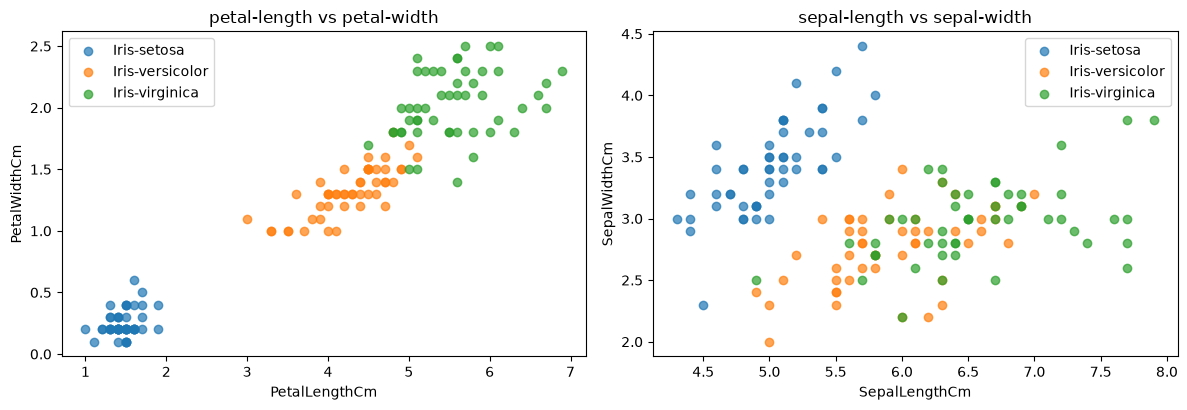

In [3]:
# petal-length vs petal-width: สอง feature นี้แยก class ได้ชัดที่สุด
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for k, name in enumerate(class_names):
    m = species_all == name
    ax[0].scatter(X_all[m, 2], X_all[m, 3], label=name, alpha=.7)
    ax[1].scatter(X_all[m, 0], X_all[m, 1], label=name, alpha=.7)
ax[0].set(title="petal-length vs petal-width", xlabel=FEATURES[2], ylabel=FEATURES[3]); ax[0].legend()
# sepal ซ้อนกันมากกว่า petal: versicolor/virginica แยกด้วย sepal ได้ยาก
ax[1].set(title="sepal-length vs sepal-width", xlabel=FEATURES[0], ylabel=FEATURES[1]); ax[1].legend()
fig.tight_layout(); plt.show()

In [4]:
# ตรวจคุณภาพข้อมูล: ค่าเป็นทศนิยม 1 ตำแหน่งตาม Iris มาตรฐานหรือไม่ มีกี่ค่าที่ไม่ซ้ำ
for j, f in enumerate(FEATURES):
    print(f"{f:<14} เป็นจำนวนเต็มทุกตัว: {bool(np.all(X_all[:, j] == np.round(X_all[:, j])))}  ค่าที่ไม่ซ้ำ: {len(np.unique(X_all[:, j]))}")

# ตรวจแถวซ้ำ และแถวที่ feature เหมือนกันแต่ class ต่างกัน (ถ้ามี จะไม่มีโมเดลไหนทายถูกได้ทั้งคู่)
rows, inv = np.unique(X_all, axis=0, return_inverse=True)
inv = inv.ravel()
print(f"\nแถวที่ไม่ซ้ำกัน {len(rows)} จาก {len(X_all)} แถว")
for r in range(len(rows)):
    labels = set(species_all[inv == r])
    if len(labels) > 1:
        print("feature เหมือนกันแต่ class ต่างกัน:", rows[r], sorted(labels))
if all(len(set(species_all[inv == r])) == 1 for r in range(len(rows))):
    print("ไม่มีแถวที่ feature เหมือนกันแต่ class ต่างกัน")

SepalLengthCm  เป็นจำนวนเต็มทุกตัว: False  ค่าที่ไม่ซ้ำ: 35
SepalWidthCm   เป็นจำนวนเต็มทุกตัว: False  ค่าที่ไม่ซ้ำ: 23
PetalLengthCm  เป็นจำนวนเต็มทุกตัว: False  ค่าที่ไม่ซ้ำ: 43
PetalWidthCm   เป็นจำนวนเต็มทุกตัว: False  ค่าที่ไม่ซ้ำ: 22

แถวที่ไม่ซ้ำกัน 147 จาก 150 แถว
ไม่มีแถวที่ feature เหมือนกันแต่ class ต่างกัน


## 1. เปรียบเทียบประสิทธิภาพและความเร็ว
ทุกวิธีเทรนด้วย train 80% แล้ววัดบน test 20% · จับเวลา fit และ predict ด้วย `compare()` ใน `ensemble.py`
เทียบ ensemble กับ base classifier ตัวเดียวที่ใช้ข้างใน: Bagging เทียบกับ Decision Tree เต็มต้น, AdaBoost เทียบกับ Decision Stump

Model                              Train acc  Test acc   Fit (s)  Predict (s)
Decision Tree (single)                1.0000    0.9333     0.001       0.0000
Bagging 50 trees (parallel)           1.0000    0.9333     0.276       0.0014
Bagging 50 trees (sequential)         1.0000    0.9333     0.038       0.0013
Decision Stump (single)               0.6667    0.6667     0.000       0.0000
AdaBoost SAMME 50 rounds              1.0000    0.9333     0.011       0.0005


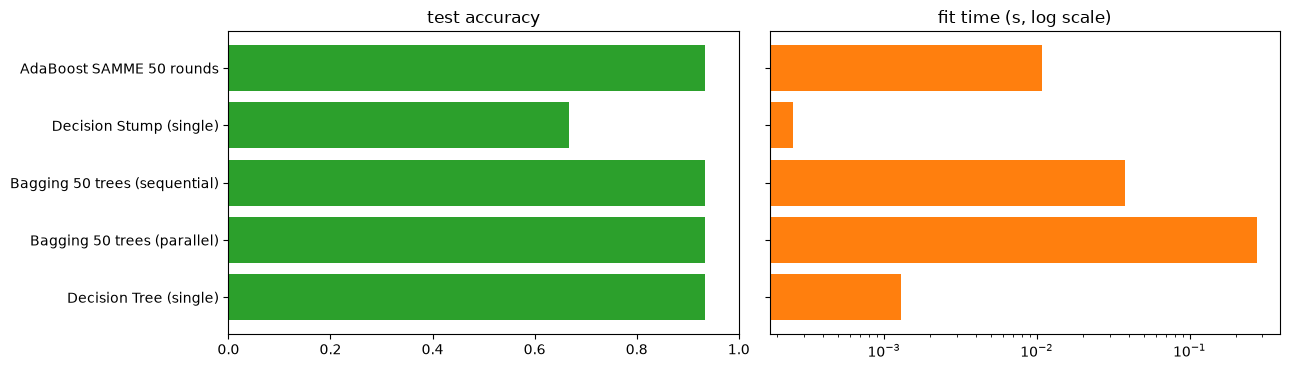

In [5]:
from ensemble import compare

rows = compare(X_tr, y_tr, X_te, y_te, n_estimators=50)
print(f"{'Model':<34}{'Train acc':>10}{'Test acc':>10}{'Fit (s)':>10}{'Predict (s)':>13}")
for r in rows:
    print(f"{r['model']:<34}{r['train_acc']:>10.4f}{r['test_acc']:>10.4f}{r['fit_s']:>10.3f}{r['predict_s']:>13.4f}")

# โมเดลที่ใช้ต่อในส่วนอื่น (seed เดียวกับในตาราง ผลจึงเหมือนกัน)
tree  = DecisionTree(random_state=0).fit(X_tr, y_tr)
stump = DecisionTree(max_depth=1, random_state=0).fit(X_tr, y_tr)
bag   = BaggingClassifier(n_estimators=50, parallel=False, seed=0).fit(X_tr, y_tr)
ada   = AdaBoostSAMME(n_estimators=50, seed=0).fit(X_tr, y_tr)

# กราฟแท่ง: accuracy และเวลา fit ของแต่ละวิธี
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
names = [r["model"] for r in rows]
ax[0].barh(names, [r["test_acc"] for r in rows], color="tab:green"); ax[0].set(xlim=(0, 1), title="test accuracy")
ax[1].barh(names, [r["fit_s"] for r in rows], color="tab:orange"); ax[1].set(xscale="log", title="fit time (s, log scale)")
ax[1].set_yticklabels([])
fig.tight_layout(); plt.show()

## 2. Accuracy ตามจำนวนโมเดลย่อย
เพราะ test set มีแค่ 45 ตัว ผลบน seed เดียวจึงแกว่ง กราฟ Bagging จึงเฉลี่ยจาก 10 seed

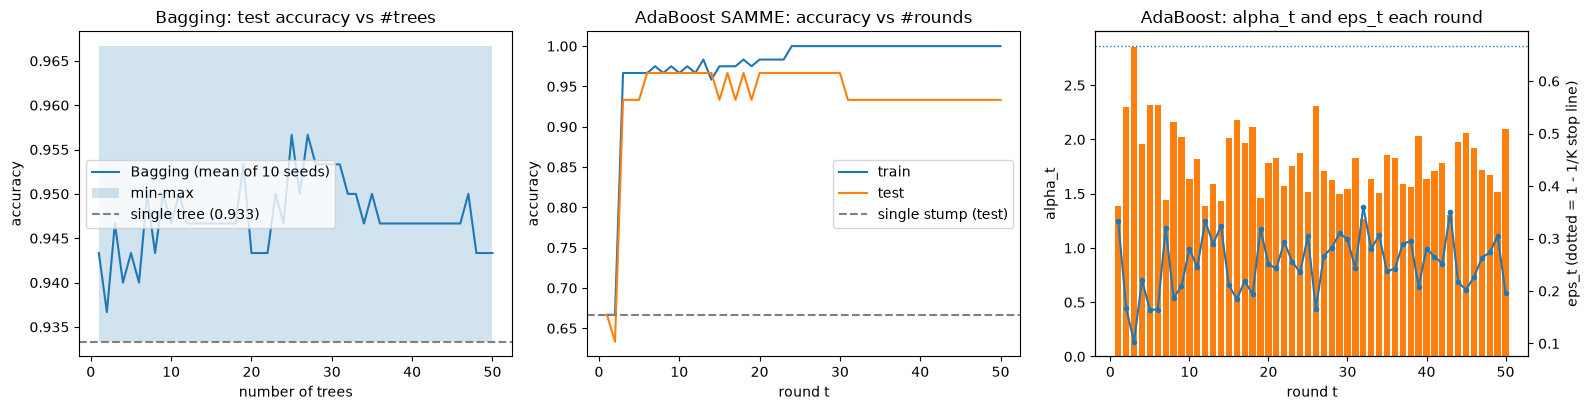

In [6]:
B = 50
bag_curves = np.array([BaggingClassifier(B, seed=s).fit(X_tr, y_tr).staged_score(X_te, y_te) for s in range(10)])
tree_acc = np.mean([accuracy(y_te, DecisionTree(random_state=s).fit(X_tr, y_tr).predict(X_te)) for s in range(10)])

ada_test = ada.staged_score(X_te, y_te)
ada_train = ada.staged_score(X_tr, y_tr)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(1, B + 1)
ax[0].plot(x, bag_curves.mean(0), label="Bagging (mean of 10 seeds)")
ax[0].fill_between(x, bag_curves.min(0), bag_curves.max(0), alpha=.2, label="min-max")
ax[0].axhline(tree_acc, color="gray", ls="--", label=f"single tree ({tree_acc:.3f})")
ax[0].set(title="Bagging: test accuracy vs #trees", xlabel="number of trees", ylabel="accuracy")
ax[0].legend()

t = np.arange(1, len(ada.alphas_) + 1)
ax[1].plot(t, ada_train, label="train")
ax[1].plot(t, ada_test, label="test")
ax[1].axhline(accuracy(y_te, stump.predict(X_te)), color="gray", ls="--", label="single stump (test)")
ax[1].set(title="AdaBoost SAMME: accuracy vs #rounds", xlabel="round t", ylabel="accuracy")
ax[1].legend()

ax[2].bar(t, ada.alphas_, color="tab:orange", label="alpha_t")
ax2 = ax[2].twinx()
ax2.plot(t, ada.errors_, color="tab:blue", marker=".", label="weighted error eps_t")
ax2.axhline(1 - 1/3, color="tab:blue", ls=":", lw=1)
ax[2].set(title="AdaBoost: alpha_t and eps_t each round", xlabel="round t", ylabel="alpha_t")
ax2.set_ylabel("eps_t (dotted = 1 - 1/K stop line)")
fig.tight_layout(); plt.show()

### 2.1 ตรวจ ε และ α รอบแรกด้วยมือ
รอบแรกทุกตัวอย่างมีน้ำหนัก 1/n เท่ากัน ε₁ จึงเท่ากับ (จำนวนที่ทายผิด) / n ตรงๆ แล้ว α₁ = ln((1−ε₁)/ε₁) + ln(K−1)

In [7]:
# stump รอบแรกเทรนด้วยน้ำหนักเท่ากัน จึงเหมือน stump ธรรมดา
first = ada.estimators_[0]
miss1 = first.predict(X_tr) != y_tr
n, K = len(y_tr), 3
eps1 = miss1.sum() / n                       # น้ำหนักเท่ากัน -> นับจำนวนผิดหาร n ได้เลย
alpha1 = np.log((1 - eps1) / eps1) + np.log(K - 1)
print(f"stump รอบแรกแบ่งด้วย {FEATURES[first.feature_[0]]} <= {first.threshold_[0]:.2f}")
print(f"ทายผิด {miss1.sum()} จาก {n} ตัว -> eps_1 = {eps1:.4f}   (ada.errors_[0] = {ada.errors_[0]:.4f})")
print(f"alpha_1 = ln({1-eps1:.4f}/{eps1:.4f}) + ln({K-1}) = {alpha1:.4f}   (ada.alphas_[0] = {ada.alphas_[0]:.4f})")
# stump ลึก 1 ชั้นแบ่งได้แค่ 2 ฝั่ง จึงทายได้แค่ 2 จาก 3 class -> ผิดทั้ง class ที่เหลือ (35 ตัว = 1/3)
print("class ที่ stump ทาย:", np.unique(first.predict(X_tr)))

stump รอบแรกแบ่งด้วย PetalLengthCm <= 2.60
ทายผิด 40 จาก 120 ตัว -> eps_1 = 0.3333   (ada.errors_[0] = 0.3333)
alpha_1 = ln(0.6667/0.3333) + ln(2) = 1.3863   (ada.alphas_[0] = 1.3863)
class ที่ stump ทาย: [0 1]


## 3. Bagging: Parallel vs Sequential
จับเวลาการ `fit` ของ Bagging แบบขนาน (ProcessPoolExecutor) เทียบกับแบบวนลูปธรรมดา

B=   10  parallel 0.289s   sequential 0.006s


B=   50  parallel 0.283s   sequential 0.039s


B=  200  parallel 0.298s   sequential 0.152s


B= 1000  parallel 0.503s   sequential 0.761s


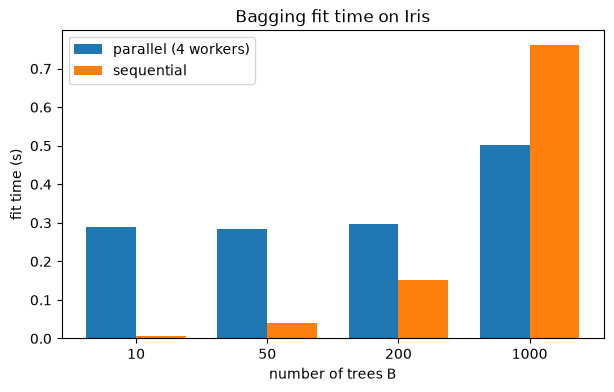

In [8]:
import os
sizes = [10, 50, 200, 1000]
t_par, t_seq = [], []
for b in sizes:
    t0 = time.perf_counter(); BaggingClassifier(b, parallel=True,  seed=0).fit(X_tr, y_tr); t_par.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); BaggingClassifier(b, parallel=False, seed=0).fit(X_tr, y_tr); t_seq.append(time.perf_counter() - t0)
    print(f"B={b:5d}  parallel {t_par[-1]:.3f}s   sequential {t_seq[-1]:.3f}s")

w = 0.38; xi = np.arange(len(sizes))
plt.figure(figsize=(7, 4))
plt.bar(xi - w/2, t_par, w, label=f"parallel ({BaggingClassifier().max_workers} workers)")
plt.bar(xi + w/2, t_seq, w, label="sequential")
plt.xticks(xi, sizes); plt.xlabel("number of trees B"); plt.ylabel("fit time (s)")
plt.title("Bagging fit time on Iris"); plt.legend(); plt.show()

### 3.1 parallel เร็วกว่าเมื่อไหร่
ส่วนที่ 3: บน Iris parallel ใช้ราว 0.3 s เกือบคงที่ (ต้นทุนเปิด worker 4 process ซึ่งต้องเปิด Python ใหม่และ import numpy) ส่วน sequential โตตาม B จนที่ B = 1000 parallel ก็เร็วกว่าแล้ว
parallel คุ้มเมื่องานแต่ละชิ้นใหญ่กว่าต้นทุนนี้ จึงทดลองให้ต้นไม้แต่ละต้นเทรนนานขึ้น
- **base model = `DecisionTree` ที่เขียนเอง** ต้นเต็ม เวลาเทรนโตตามขนาดข้อมูล (ราว n log n ต่อชั้น)
- **ข้อมูล = Iris ขยายขนาด**: สุ่ม Iris train แบบใส่คืนให้ได้ n ตัว แล้วบวก noise (σ = 0.8) ให้ class ซ้อนกันมากขึ้น ต้นไม้จึงลึกและเทรนนานขึ้น ยังเป็น 4 feature 3 class เหมือนเดิม
- B = 16 ต้น, 4 process (เวลา parallel รวมเวลาเปิด process แล้ว)

n=  500  parallel   0.28s   sequential   0.13s   speedup x0.47   (test acc 0.967)


n= 2000  parallel   0.41s   sequential   0.59s   speedup x1.44   (test acc 0.933)


n= 5000  parallel   0.84s   sequential   1.44s   speedup x1.71   (test acc 0.933)


n=10000  parallel   1.27s   sequential   3.04s   speedup x2.39   (test acc 0.833)


n=20000  parallel   2.38s   sequential   6.19s   speedup x2.60   (test acc 0.900)


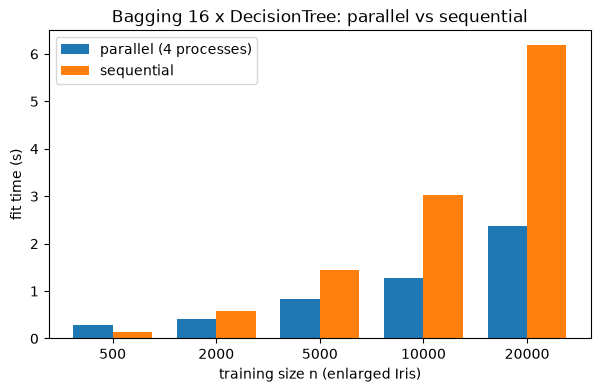

In [9]:
def enlarge_iris(n, sigma=0.8, seed=0):
    """สุ่ม Iris train แบบใส่คืนให้ได้ n ตัว + บวก Gaussian noise"""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(X_tr), n)
    return X_tr[idx] + rng.normal(0, sigma, (n, X_tr.shape[1])), y_tr[idx]

sizes_n = [500, 2000, 5000, 10000, 20000]
res = []
for n in sizes_n:
    Xb, yb = enlarge_iris(n)
    row = {}
    for mode in (True, False):
        t0 = time.perf_counter()
        m = BaggingClassifier(16, max_workers=4, parallel=mode, seed=0, base=DecisionTree).fit(Xb, yb)
        row["parallel" if mode else "sequential"] = time.perf_counter() - t0
    res.append(row)
    print(f"n={n:5d}  parallel {row['parallel']:6.2f}s   sequential {row['sequential']:6.2f}s   "
          f"speedup x{row['sequential'] / row['parallel']:.2f}   (test acc {accuracy(y_te, m.predict(X_te)):.3f})")

xi = np.arange(len(sizes_n)); w = 0.38
plt.figure(figsize=(7, 4))
plt.bar(xi - w/2, [r["parallel"] for r in res], w, label="parallel (4 processes)")
plt.bar(xi + w/2, [r["sequential"] for r in res], w, label="sequential")
plt.xticks(xi, sizes_n); plt.xlabel("training size n (enlarged Iris)"); plt.ylabel("fit time (s)")
plt.title("Bagging 16 x DecisionTree: parallel vs sequential"); plt.legend(); plt.show()

## 4. Confusion matrix บน test set

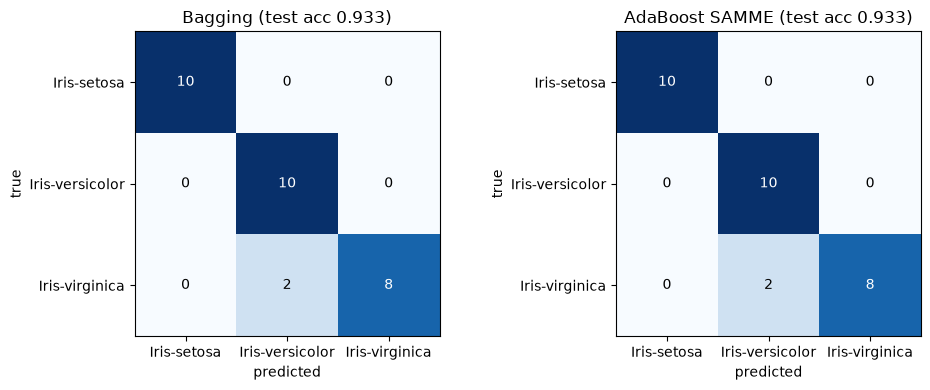

In [10]:
def confusion(y, p, K=3):
    cm = np.zeros((K, K), int)
    np.add.at(cm, (y, p), 1)  # แถว = class จริง, คอลัมน์ = class ที่ทาย
    return cm

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, m) in zip(ax, [("Bagging", bag), ("AdaBoost SAMME", ada)]):
    cm = confusion(y_te, m.predict(X_te))
    a.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    a.set(title=f"{name} (test acc {accuracy(y_te, m.predict(X_te)):.3f})", xlabel="predicted", ylabel="true",
          xticks=range(3), yticks=range(3), xticklabels=class_names, yticklabels=class_names)
fig.tight_layout(); plt.show()

## 5. วิเคราะห์ผล
ตัวเลขทุกตัวมาจากผลที่รันได้ด้านบน (test set 30 ตัว: ทายผิดเพิ่ม 1 ตัว = accuracy ลด 0.0333) · ทุกโมเดลใช้ Decision Tree ที่เขียนเองด้วย NumPy

**1. Bagging ดีกว่า Decision Tree ต้นเดียวไหม?**
ที่ seed 0 ได้ test 0.9333 เท่ากัน แต่ค่าเฉลี่ย 10 seed ในกราฟส่วนที่ 2 Bagging 50 ต้นได้ 0.9433 (บาง seed ได้ 0.9667) ส่วนต้นเดียวได้ 0.9333 ทุก seed Bagging จึงดีกว่าเล็กน้อยโดยเฉลี่ย ตรงกับทฤษฎีว่าการโหวตหลายต้นช่วยลด variance
- ข้อมูลง่าย: ส่วนที่ 0 แสดงว่า petal แยก setosa ได้ขาด และแยก versicolor/virginica ได้เกือบหมด ต้นเดียวก็ทำได้ดีอยู่แล้ว
- train accuracy = 1.0 ทุกโมเดลที่ไม่ใช่ stump เพราะชุดนี้ไม่มีแถวที่ feature เหมือนกันแต่ class ต่างกัน

**2. AdaBoost ยก stump ขึ้นมาได้เท่าไหร่ และ train accuracy เป็นอย่างไรตามจำนวนรอบ**
stump ตัวเดียวได้ 0.6667 เพราะแบ่งได้ครั้งเดียว (`PetalLengthCm <= 2.60`) ทายได้แค่ 2 class ผิดทั้ง class ที่เหลือ 40 ตัว (ส่วนที่ 2.1) AdaBoost ยก test ขึ้นเป็น 0.9667 ที่ 10 รอบ และ 0.9333 ที่ 50 รอบ
- train accuracy: รอบ 1–2 = 0.6667, รอบ 3 กระโดดเป็น 0.9667 (stump ใหม่แยก versicolor/virginica ได้) และถึง 1.0 ที่รอบ 24
- test สูงสุด 0.9667 แล้วลดเหลือ 0.9333 ตั้งแต่รอบ 41 ต่างกัน 1 ตัวอย่าง เพิ่มรอบต่อจาก ~10 จึงไม่ได้ช่วยบน test

**3. α_t สัมพันธ์กับ ε_t อย่างไร**
α_t = ln((1−ε_t)/ε_t) + ln(K−1) ลดลงเมื่อ ε_t เพิ่ม: stump ที่แม่นกว่าได้เสียงโหวตมากกว่า เช่น รอบ 3 ε ต่ำสุด 0.103 ได้ α สูงสุด 2.85 ส่วนรอบ 1 ε = 1/3 ได้ α = ln 2 + ln 2 = 1.386 (ตรวจด้วยมือในส่วนที่ 2.1)
- หลังอัปเดตทุกรอบ น้ำหนักรวมของตัวที่ทายผิดเป็น 2/3 พอดี (ดู `python ensemble.py --verbose`) stump รอบถัดไปจึงถูกบังคับให้แก้ตัวพวกนั้น

**4. ความเร็วของแต่ละวิธี**
จากตารางส่วนที่ 1: fit ของ AdaBoost (~0.01 s) เร็วกว่า Bagging แบบ sequential (~0.04 s) เพราะ stump แบ่งครั้งเดียว ส่วนต้นเต็มต้องแตกกิ่งจนสุด Bagging แบบ parallel ใช้ราว 0.3 s เวลาทำนายของ ensemble ทุกแบบราว 1 ms
- parallel ช้ากว่าบน Iris ที่ B = 50 เพราะต้นทุนคงที่ของการเปิด worker 4 process (เปิด Python ใหม่และ import numpy) ราว 0.3 s แต่ต้นทุนนี้ต่ำกว่าตอนใช้ sklearn มาก (ราว 1.8 s) เพราะ worker ไม่ต้อง import sklearn แล้ว
- ส่วนที่ 3: ที่ B = 1000 parallel เร็วกว่าแล้ว (ราว 0.5 s เทียบ 0.76 s)
- ส่วนที่ 3.1: เมื่อแต่ละต้นเทรนนานขึ้น parallel เร็วกว่าตั้งแต่ n = 2,000 (ราว ×1.4) จนราว ×2.6 ที่ n = 20,000 (เวลาต่างไปเล็กน้อยทุกครั้งที่รัน)
- AdaBoost ทำ parallel ไม่ได้ตั้งแต่ต้น เพราะรอบ t ต้องรอน้ำหนักจากรอบ t−1

**5. class ไหนสับสนกันบ่อยที่สุด**
virginica → versicolor: ทั้ง Decision Tree, Bagging และ AdaBoost ได้ confusion matrix เหมือนกัน setosa และ versicolor ถูกหมด 10/10 ส่วน virginica ถูกทายเป็น versicolor 2 ตัว สอดคล้องกับ scatter ในส่วนที่ 0 ที่ versicolor/virginica ซ้อนกันบริเวณ petal-width ราว 1.5–1.8

## 6. (เพิ่มเติม) AdaBoost: Decision Stump vs ต้นลึก 2 ชั้น
weak learner ที่แรงขึ้น (max_depth=2) ช่วยหรือไม่

weak learner       T  rounds   Train    Test
max_depth=1       10      10  0.9667  0.9667


max_depth=1       50      50  1.0000  0.9333
max_depth=2       10      10  1.0000  0.9333
max_depth=2       50      50  1.0000  0.9333
single depth-2                0.9667  0.9333


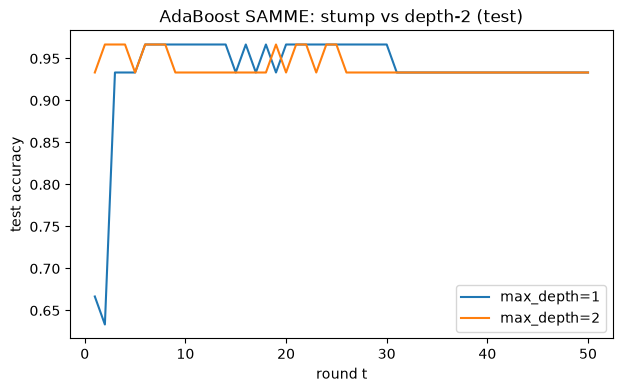

In [11]:
print(f"{'weak learner':<16}{'T':>4}{'rounds':>8}{'Train':>8}{'Test':>8}")
curves = {}
for depth in [1, 2]:
    for T in [10, 50]:
        a = AdaBoostSAMME(n_estimators=T, max_depth=depth, seed=0).fit(X_tr, y_tr)
        print(f"{'max_depth=' + str(depth):<16}{T:>4}{len(a.alphas_):>8}"
              f"{accuracy(y_tr, a.predict(X_tr)):>8.4f}{accuracy(y_te, a.predict(X_te)):>8.4f}")
        curves[depth] = a.staged_score(X_te, y_te)  # เก็บกราฟของ T=50
# เทียบกับต้นลึก 2 ชั้นต้นเดียว (ไม่ boosting)
d2 = DecisionTree(max_depth=2, random_state=0).fit(X_tr, y_tr)
print(f"{'single depth-2':<16}{'':>4}{'':>8}{accuracy(y_tr, d2.predict(X_tr)):>8.4f}{accuracy(y_te, d2.predict(X_te)):>8.4f}")

plt.figure(figsize=(7, 4))
for depth, c in curves.items():
    plt.plot(np.arange(1, len(c) + 1), c, label=f"max_depth={depth}")
plt.xlabel("round t"); plt.ylabel("test accuracy")
plt.title("AdaBoost SAMME: stump vs depth-2 (test)"); plt.legend(); plt.show()

**สรุปส่วนที่ 6**: weak learner ที่แรงขึ้น (max_depth=2) ทำให้ train ลู่เข้าเร็วขึ้น (ได้ 1.0 ตั้งแต่ T=10 ส่วน stump ต้องใช้ 24 รอบ) แต่ test ไม่ดีขึ้น: max_depth=2 ได้ 0.9333 ทั้ง T=10 และ T=50 ส่วน stump ได้ 0.9667 ที่ T=10 และ 0.9333 ที่ T=50 ต่างกันแค่ 1 ตัวอย่าง ต้นลึก 2 ชั้นต้นเดียวได้ 0.9333 อยู่แล้ว boosting จึงเพิ่มไม่ได้ เพราะต้นลึก 2 ชั้นแยก 3 class ได้เกือบหมด เหลือ bias ให้ลดน้อย ตามทฤษฎี AdaBoost ใช้ stump เป็นค่าเริ่มต้นต่อไป